# Semantic Search SciFact — Jupyter Laptop

Notebook lokal untuk fine-tuning MiniLM dengan MNRL, exact cosine retrieval, evaluasi, grafik perbandingan, matriks transisi Hit@10, dan demo pencarian.

**Cara menjalankan:** buka notebook ini melalui Jupyter Notebook, JupyterLab, atau VS Code dengan kernel Python lokal. Jalankan cell 01 instalasi sekali, restart kernel jika diminta, lalu jalankan dari cell 02 secara berurutan. Akses Internet dibutuhkan untuk instalasi dan unduhan awal Hugging Face. Tidak diperlukan akun Colab/Kaggle.

**Perangkat:** NVIDIA CUDA dipakai bila tersedia pada PyTorch; selain itu CPU. Environment Python yang diperiksa saat pembuatan adalah Python 3.13.7 dengan PyTorch 2.13.0+cpu; CUDA tidak terdeteksi pada environment tersebut. Kernel Jupyter yang dipilih dapat berbeda, sehingga cell 02 memeriksa ulang perangkat dan lokasi Python yang benar-benar dipakai.

**Output:** `outputs/scifact_laptop/` di direktori kerja Jupyter, dengan ZIP di `outputs/scifact_laptop_artifacts.zip`. Path absolut dicetak pada cell 02. Buka Jupyter dari folder proyek untuk memudahkan penelusuran file.

**Konfigurasi laptop:** train batch 8, encode batch 16, FP32, 3 epoch. Pengurangan batch MNRL dapat mengubah hasil eksperimen karena mengubah in-batch negatives. Hasil run laptop tidak diasumsikan identik dengan run Colab batch 16. Tentukan konfigurasi sebelum melihat hasil test.

**Status:** seluruh output salinan ini dikosongkan; output Colab tidak dianggap hasil laptop. Sintaks dan fungsi inti diperiksa lokal, tetapi training penuh belum dijalankan dengan environment laptop.

Untuk menghindari konflik paket lingkungan umum, gunakan virtual environment terpisah. Langkah lengkap tersedia di `PANDUAN-JUPYTER-LAPTOP.md`. Notebook ini tetap berisi seluruh kode dan tidak memerlukan notebook lama atau script generator untuk dijalankan.


## 01 · Instalasi pada kernel Jupyter lokal

Jalankan sekali di virtual environment khusus penelitian. `%pip` memasang paket ke kernel aktif. PyTorch yang sudah memenuhi batas versi dipertahankan; jangan mengganti build CUDA yang sudah berfungsi. Jika PyTorch belum terpasang, pip akan memasangnya beserta dependensi lain. Untuk konfigurasi GPU NVIDIA yang sesuai, gunakan [pemilih instalasi resmi PyTorch](https://pytorch.org/get-started/locally/).

Sesudah instalasi, restart kernel lalu lanjut dari cell 02. Tidak perlu mengulang instalasi setiap membuka notebook. Versi library penelitian dipertahankan dari notebook sumber; kompatibilitas penuh perlu diperiksa pada run pertama.


In [1]:
%pip install "torch>=2.6,<3.0" "sentence-transformers==5.1.2" "transformers==4.57.1" "datasets==4.3.0" "accelerate==1.11.0" "huggingface-hub<1.0" numpy pandas matplotlib ipywidgets


   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
    --------------------------------------- 0.3/12.0 MB ? eta -:--:--
    --------------------------------------- 0.3/12.0 MB ? eta -:--:--
    --------------------------------------- 0.3/12.0 MB ? eta -:--:--
    --------------------------------------- 0.3/12.0 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.0 MB 280.5 kB/s eta 0:00:41
   - -------------------------------------- 0.5/12.0 MB 280.5 kB/s eta 0:00:41
   - -------------------------------------- 0.5/12.0 MB 280.5 kB/s eta 0:00:41
   - -------------------------------------- 0.5/12.0 MB 280.5 kB/s eta 0:00:41
   - -------------------------------------- 0.5/12.0 MB 280.5 kB/s eta 0:00:41
   -- ------------------------------------- 0.8/12.0 MB 282.8 kB/s eta 0:00:40
   -- ------------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 02 · Konfigurasi laptop, CPU/GPU, dan lokasi output

Satu GPU dipakai jika CUDA tersedia; tanpa CUDA, training tetap dapat berjalan pada CPU dengan batch lebih kecil. CPU dapat lebih lambat. Jumlah thread dibatasi hingga empat sebagai titik awal untuk laptop. Konfigurasi dan lokasi interpreter disimpan bersama hasil.


In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # Harus sebelum import torch.
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import gc, hashlib, json, random, re, shutil, subprocess, sys, time
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from huggingface_hub import HfApi
from sentence_transformers import (
    SentenceTransformer, SentenceTransformerTrainer,
    SentenceTransformerTrainingArguments, losses,
)
from sentence_transformers.training_args import BatchSamplers
from transformers import set_seed
from IPython.display import display

CFG = {
    "seed": 42, "model_id": "sentence-transformers/all-MiniLM-L6-v2",
    "model_revision": "main", "data_revision": "main", "qrels_revision": "main",
    "epochs": 3, "learning_rate": 2e-5, "train_batch_size": 8,
    "encode_batch_size": 16, "warmup_ratio": 0.1,
    "weight_decay": 0.01, "max_seq_length": 256,
    "fp16": False, "eval_depth": 100, "display_top_k": 5,
}
set_seed(CFG["seed"])
random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
CPU_THREADS = min(4, os.cpu_count() or 1)
torch.set_num_threads(CPU_THREADS)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = (Path.cwd() / "outputs" / "scifact_laptop").resolve()
ROOT.mkdir(parents=True, exist_ok=True)

def save_json(value, path):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

environment = {"python": sys.version, "python_executable": sys.executable,
    "working_directory": str(Path.cwd()), "output_directory": str(ROOT),
    "cpu_threads": CPU_THREADS, "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "packages": {name: version(name) for name in (
        "torch", "sentence-transformers", "transformers", "datasets", "accelerate", "huggingface-hub", "numpy", "pandas")}}
save_json(environment, ROOT / "environment.json")
print(json.dumps(environment, indent=2))
if DEVICE == "cpu":
    print("Mode CPU aktif. Training tetap dapat berjalan; durasi bergantung perangkat laptop.")

print("Output lokal:", ROOT)
print("Kernel Python:", sys.executable)


{
  "python": "3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]",
  "python_executable": "c:\\Users\\amrin\\AppData\\Local\\Programs\\Python\\Python313\\python.exe",
  "working_directory": "c:\\Users\\amrin\\OneDrive\\Desktop\\kuli\\TKI",
  "output_directory": "C:\\Users\\amrin\\OneDrive\\Desktop\\kuli\\TKI\\outputs\\scifact_laptop",
  "cpu_threads": 4,
  "device": "cpu",
  "gpu": null,
  "packages": {
    "torch": "2.13.0",
    "sentence-transformers": "5.1.2",
    "transformers": "4.57.1",
    "datasets": "4.3.0",
    "accelerate": "1.11.0",
    "huggingface-hub": "0.36.2",
    "numpy": "2.2.5",
    "pandas": "3.0.2"
  }
}
Mode CPU aktif. Training tetap dapat berjalan; durasi bergantung perangkat laptop.
Output lokal: C:\Users\amrin\OneDrive\Desktop\kuli\TKI\outputs\scifact_laptop
Kernel Python: c:\Users\amrin\AppData\Local\Programs\Python\Python313\python.exe


## 03 · Catat revision dan muat dataset

Corpus dan queries memiliki nama split khusus; train/test ditentukan oleh qrels. Commit model dan dataset dicatat agar eksperimen dapat diulang dengan revision yang sama.


In [3]:
api = HfApi()
revisions = {
    "model": api.model_info(CFG["model_id"], revision=CFG["model_revision"]).sha,
    "data": api.dataset_info("BeIR/scifact", revision=CFG["data_revision"]).sha,
    "qrels": api.dataset_info("BeIR/scifact-qrels", revision=CFG["qrels_revision"]).sha,
}
save_json({"config": CFG, "resolved_revisions": revisions}, ROOT / "experiment_config.json")
corpus_raw = load_dataset("BeIR/scifact", "corpus", split="corpus", revision=revisions["data"])
queries_raw = load_dataset("BeIR/scifact", "queries", split="queries", revision=revisions["data"])
qrels_train_raw = load_dataset("BeIR/scifact-qrels", split="train", revision=revisions["qrels"])
qrels_test_raw = load_dataset("BeIR/scifact-qrels", split="test", revision=revisions["qrels"])
print("Corpus:", len(corpus_raw), "Queries:", len(queries_raw))
print("Qrels train:", len(qrels_train_raw), "Qrels test:", len(qrels_test_raw))
print(corpus_raw.column_names, queries_raw.column_names, qrels_train_raw.column_names)


README.md: 0.00B [00:00, ?B/s]

c:\Users\amrin\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\amrin\.cache\huggingface\hub\datasets--BeIR--scifact. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to re

corpus-00000-of-00001.parquet:   0%|          | 0.00/4.47M [00:00<?, ?B/s]

Generating corpus split:   0%|          | 0/5183 [00:00<?, ? examples/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


queries-00000-of-00001.parquet:   0%|          | 0.00/65.0k [00:00<?, ?B/s]

... (4 outputs left out)

test.tsv: 0.00B [00:00, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Corpus: 5183 Queries: 1109
Qrels train: 919 Qrels test: 339
['_id', 'title', 'text'] ['_id', 'title', 'text'] ['query-id', 'corpus-id', 'score']


## 04 · Normalisasi dan pemeriksaan ID

Hanya rapikan whitespace. Pertahankan istilah, negasi, angka, satuan, dan tanda baca. ID dikonversi ke string karena tipe ID corpus dan qrels berbeda. Data bermasalah menghentikan proses agar tidak mengubah benchmark diam-diam.


In [4]:
def clean_text(value):
    return re.sub(r"\s+", " ", str(value or "")).strip()

def build_records(rows, kind):
    records = {}
    for row in rows:
        assert row.get("_id") is not None, f"ID kosong: {kind}"
        rid = str(row["_id"]).strip()
        assert rid and rid not in records, f"ID kosong/duplikat: {kind} {rid}"
        title, text = clean_text(row.get("title")), clean_text(row.get("text"))
        if kind == "corpus":
            model_text = " ".join(part for part in [title, text] if part)
            records[rid] = {"_id": rid, "title": row.get("title") or "", "text": row.get("text") or "", "model_text": model_text}
        else:
            model_text = text
            records[rid] = {"_id": rid, "text": row.get("text") or "", "model_text": text}
        assert model_text, f"Teks kosong: {kind} {rid}"
    return records

corpus = build_records(corpus_raw, "corpus")
queries = build_records(queries_raw, "queries")

def build_qrels(rows):
    judgments = {}
    seen = set()
    for row in rows:
        qid, did, score = str(row["query-id"]), str(row["corpus-id"]), int(row["score"])
        assert qid in queries and did in corpus, f"Referensi ID hilang: {qid}, {did}"
        assert (qid, did) not in seen, f"Qrels duplikat: {qid}, {did}"
        seen.add((qid, did))
        assert score == 1, "Evaluator notebook ini dirancang untuk qrels biner positif SciFact."
        judgments.setdefault(qid, {})[did] = score
    return judgments

qrels_train = build_qrels(qrels_train_raw)
qrels_test = build_qrels(qrels_test_raw)
train_qids, test_qids = sorted(qrels_train), sorted(qrels_test)
assert not set(train_qids) & set(test_qids), "Query train/test tumpang tindih."
doc_ids = sorted(corpus)
doc_texts = [corpus[did]["model_text"] for did in doc_ids]
assert len(doc_ids) >= CFG["eval_depth"]
audit = {"corpus_before": len(corpus_raw), "corpus_after": len(corpus),
    "queries_total": len(queries), "train_queries": len(train_qids), "test_queries": len(test_qids),
    "train_qrels": len(qrels_train_raw), "test_qrels": len(qrels_test_raw),
    "unused_queries": len(set(queries) - set(train_qids) - set(test_qids)),
    "filtered_records": 0, "normalization": "whitespace only; title + space + abstract"}
save_json(audit, ROOT / "data_audit.json")
save_json([corpus[d] for d in doc_ids], ROOT / "documents.json")
save_json(doc_ids, ROOT / "doc_ids.json")
print(json.dumps(audit, indent=2))


{
  "corpus_before": 5183,
  "corpus_after": 5183,
  "queries_total": 1109,
  "train_queries": 809,
  "test_queries": 300,
  "train_qrels": 919,
  "test_qrels": 339,
  "unused_queries": 0,
  "filtered_records": 0,
  "normalization": "whitespace only; title + space + abstract"
}


## 05 · Pasangan positif untuk MNRL

Semua pasangan relevan train dipertahankan. Dataset Trainer hanya berisi dua kolom teks; ID disimpan terpisah agar tidak ikut di-encode. Tidak perlu label similarity buatan.


In [5]:
pair_rows = [
    {"query_id": qid, "document_id": did,
     "anchor": queries[qid]["model_text"], "positive": corpus[did]["model_text"]}
    for qid in train_qids for did in sorted(qrels_train[qid])
]
assert len({(p["query_id"], p["document_id"]) for p in pair_rows}) == len(pair_rows)
assert all(p["query_id"] not in qrels_test for p in pair_rows)
train_dataset = Dataset.from_dict({
    "anchor": [p["anchor"] for p in pair_rows],
    "positive": [p["positive"] for p in pair_rows],
})
pd.DataFrame(pair_rows).to_csv(ROOT / "train_pairs.csv", index=False)
audit.update({"positive_pairs": len(pair_rows),
    "unique_positive_documents": len({p["document_id"] for p in pair_rows})})
save_json(audit, ROOT / "data_audit.json")
display(pd.DataFrame(pair_rows).head(3))
print(train_dataset)


,query_id,document_id,anchor,positive
0,0,31715818,0-dimensional biomaterials lack inductive prop...,New opportunities: the use of nanotechnologies...
1,10,32587939,4-PBA treatment decreases endoplasmic reticulu...,Wolfram syndrome 1 and adenylyl cyclase 8 inte...
2,1000,16472469,Pyridostatin stabilizes the G - quadruplex in ...,Targeting BRCA1 and BRCA2 Deficiencies with G-...


Dataset({
    features: ['anchor', 'positive'],
    num_rows: 919
})


## 06 · Muat model dan audit truncation

Batas input dipastikan dari konfigurasi, lalu statistik dihitung dengan tokenizer model sebelum truncation. Satu dokumen menghasilkan satu embedding; belum ada chunking.


In [6]:
model = SentenceTransformer(CFG["model_id"], revision=revisions["model"], device=DEVICE)
print("Batas bawaan checkpoint:", model.max_seq_length)
assert model.max_seq_length == CFG["max_seq_length"], "Periksa konfigurasi sebelum mengubah batas input."
assert model.get_sentence_embedding_dimension() == 384

def token_audit(texts):
    lengths = []
    for start in range(0, len(texts), 128):
        tokens = model.tokenizer(texts[start:start+128], truncation=False, padding=False, verbose=False)
        lengths.extend(map(len, tokens["input_ids"]))
    arr = np.asarray(lengths)
    return {"count": len(lengths), "median_tokens": float(np.median(arr)),
        "max_tokens": int(arr.max()), "truncated_count": int((arr > model.max_seq_length).sum()),
        "truncated_fraction": float((arr > model.max_seq_length).mean())}

truncation = {
    "max_seq_length": model.max_seq_length, "corpus": token_audit(doc_texts),
    "train_queries": token_audit([queries[q]["model_text"] for q in train_qids]),
    "test_queries": token_audit([queries[q]["model_text"] for q in test_qids]),
}
save_json(truncation, ROOT / "truncation_audit.json")
print(json.dumps(truncation, indent=2))


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\amrin\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\amrin\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batas bawaan checkpoint: 256
{
  "max_seq_length": 256,
  "corpus": {
    "count": 5183,
    "median_tokens": 316.0,
    "max_tokens": 1939,
    "truncated_count": 3681,
    "truncated_fraction": 0.710206444144318
  },
  "train_queries": {
    "count": 809,
    "median_tokens": 21.0,
    "max_tokens": 79,
    "truncated_count": 0,
    "truncated_fraction": 0.0
  },
  "test_queries": {
    "count": 300,
    "median_tokens": 21.0,
    "max_tokens": 64,
    "truncated_count": 0,
    "truncated_fraction": 0.0
  }
}


## 07 · Tetapkan loss dan Trainer

MNRL memakai positive lain di batch sebagai negatif. NO_DUPLICATES mengurangi konflik teks berulang, tetapi tidak menghilangkan semua false negative. Tidak ada evaluator test, early stopping, atau pemilihan checkpoint terbaik.


In [7]:
loss = losses.MultipleNegativesRankingLoss(model, scale=20.0)
args = SentenceTransformerTrainingArguments(
    output_dir=str(ROOT / "checkpoints"),
    num_train_epochs=CFG["epochs"],
    per_device_train_batch_size=CFG["train_batch_size"],
    gradient_accumulation_steps=1,
    learning_rate=CFG["learning_rate"],
    warmup_ratio=CFG["warmup_ratio"],
    weight_decay=CFG["weight_decay"],
    lr_scheduler_type="linear", optim="adamw_torch",
    use_cpu=DEVICE == "cpu",
    fp16=CFG["fp16"] and DEVICE == "cuda", bf16=False,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    dataloader_drop_last=True, dataloader_num_workers=0,
    dataloader_pin_memory=DEVICE == "cuda",
    eval_strategy="no", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=False, logging_strategy="steps", logging_steps=5,
    report_to="none", seed=CFG["seed"], data_seed=CFG["seed"],
)
trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=train_dataset, loss=loss)
print("Training hanya memakai query train. Epoch final ditetapkan:", CFG["epochs"])


Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Training hanya memakai query train. Epoch final ditetapkan: 3


## 08 · Jalankan fine-tuning

Loss digunakan untuk memantau optimisasi. Loss turun belum membuktikan ranking test membaik. Waktu yang dicatat adalah waktu aktual run ini.


In [8]:
started = time.perf_counter()
train_result = trainer.train()
training_seconds = time.perf_counter() - started
save_json({"seconds": training_seconds, "metrics": train_result.metrics}, ROOT / "training_summary.json")
save_json(trainer.state.log_history, ROOT / "training_log.json")
print(f"Training selesai: {training_seconds:.1f} detik")


Step,Training Loss
5,0.060600
10,0.090700
15,0.106800
20,0.243900
25,0.099400
30,0.045200
35,0.074200
40,0.024600
45,0.091400
50,0.118100


Training selesai: 1351.9 detik


## 09 · Simpan checkpoint final dan plot loss

Checkpoint final ini dipakai untuk corpus dan query. Checkpoint per epoch hanya untuk pemulihan, bukan dipilih berdasarkan test.


,loss,grad_norm,learning_rate,epoch,step
0,0.0606,7.875202,2.285714e-06,0.043860,5
1,0.0907,5.225788,5.142857e-06,0.087719,10
2,0.1068,9.087183,8.000000e-06,0.131579,15
3,0.2439,1.104570,1.085714e-05,0.175439,20
4,0.0994,7.196520,1.371429e-05,0.219298,25
...,...,...,...,...,...
63,0.0149,1.385117,1.498371e-06,2.807018,320
64,0.0241,7.614524,1.172638e-06,2.850877,325
65,0.0358,11.233349,8.469055e-07,2.894737,330
66,0.0476,0.475406,5.211726e-07,2.938596,335


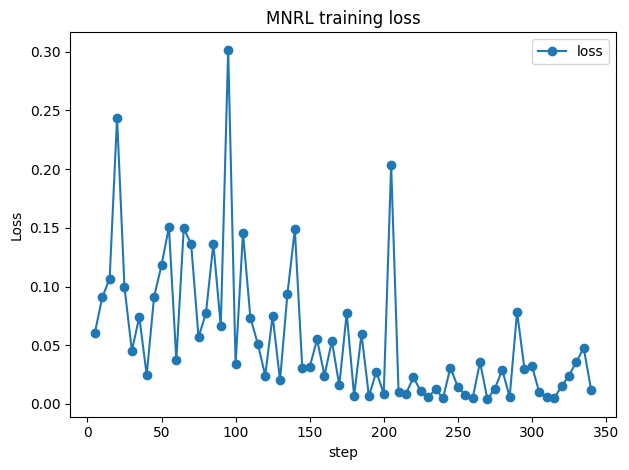

In [9]:
FINAL_MODEL = ROOT / "model_final"
model.save_pretrained(str(FINAL_MODEL))
loss_log = pd.DataFrame([x for x in trainer.state.log_history if "loss" in x])
display(loss_log)
if not loss_log.empty:
    try:
        import matplotlib.pyplot as plt
        ax = loss_log.plot(x="step", y="loss", marker="o", title="MNRL training loss")
        ax.set_ylabel("Loss")
        plt.tight_layout()
        plt.savefig(ROOT / "training_loss.png", dpi=150)
        plt.show()
    except ImportError:
        print("Matplotlib tidak tersedia; loss tetap tersimpan di training_log.json.")
# Lepaskan objek training sebelum memuat ulang checkpoint untuk inference.
del trainer, loss, model
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()


Jumlah batch: 114
Ukuran setiap batch: 8
Jumlah pasangan yang dinilai: 912


,Model,Rata-rata loss
0,Pretrained,0.101198
1,Fine-tuned,0.015606


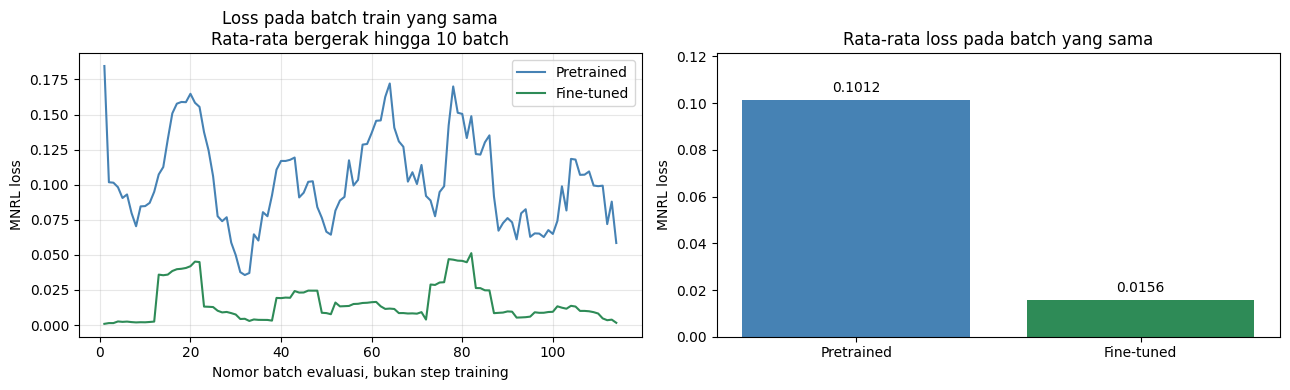

In [24]:
import json
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer, losses

# Menggunakan folder hasil notebook laptop.
RESULT_DIR = Path(ROOT)

experiment = json.loads(
    (RESULT_DIR / "experiment_config.json").read_text(encoding="utf-8")
)
config = experiment["config"]

# Kedua model menggunakan pasangan dan urutan batch yang sama.
pairs = pd.read_csv(
    RESULT_DIR / "train_pairs.csv",
    keep_default_na=False
)

pairs = pairs.sample(
    frac=1,
    random_state=config["seed"]
).reset_index(drop=True)

BATCH_SIZE = config["train_batch_size"]
device = "cuda" if torch.cuda.is_available() else "cpu"

# Hindari teks berulang di dalam batch MNRL.
batches = []
current_batch = []
used_texts = set()

for row in pairs.itertuples(index=False):
    anchor = str(row.anchor)
    positive = str(row.positive)

    if anchor in used_texts or positive in used_texts:
        continue

    current_batch.append((anchor, positive))
    used_texts.update([anchor, positive])

    if len(current_batch) == BATCH_SIZE:
        batches.append(current_batch)
        current_batch = []
        used_texts = set()

# Batch tidak lengkap tidak digunakan agar ukuran pembanding konsisten.
assert batches, "Tidak ada batch yang dapat dievaluasi."

print("Jumlah batch:", len(batches))
print("Ukuran setiap batch:", BATCH_SIZE)
print("Jumlah pasangan yang dinilai:", len(batches) * BATCH_SIZE)


def calculate_batch_losses(model_path, revision=None):
    kwargs = {"device": device}

    if revision is not None:
        kwargs["revision"] = revision

    encoder = SentenceTransformer(str(model_path), **kwargs)
    encoder.max_seq_length = config["max_seq_length"]

    loss_function = losses.MultipleNegativesRankingLoss(
        encoder,
        scale=20.0
    )

    # Mode evaluasi: dropout dinonaktifkan.
    loss_function.eval()
    batch_losses = []

    with torch.no_grad():
        for batch in batches:
            anchors = [item[0] for item in batch]
            positives = [item[1] for item in batch]

            features = []

            for texts in [anchors, positives]:
                tokens = encoder.tokenize(texts)
                tokens = {
                    key: value.to(device)
                    for key, value in tokens.items()
                }
                features.append(tokens)

            value = loss_function(features, labels=None)
            batch_losses.append(value.item())

    del loss_function, encoder
    gc.collect()

    if device == "cuda":
        torch.cuda.empty_cache()

    return np.array(batch_losses)


pretrained_losses = calculate_batch_losses(
    config["model_id"],
    revision=experiment["resolved_revisions"]["model"]
)

finetuned_losses = calculate_batch_losses(
    RESULT_DIR / "model_final"
)

comparison_loss = pd.DataFrame({
    "batch": np.arange(1, len(batches) + 1),
    "pretrained_loss": pretrained_losses,
    "finetuned_loss": finetuned_losses,
})

display(pd.DataFrame({
    "Model": ["Pretrained", "Fine-tuned"],
    "Rata-rata loss": [
        pretrained_losses.mean(),
        finetuned_losses.mean()
    ]
}))

# Garis diperhalus agar pola lebih mudah terlihat.
window = min(10, len(comparison_loss))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for column, label, color in [
    ("pretrained_loss", "Pretrained", "steelblue"),
    ("finetuned_loss", "Fine-tuned", "seagreen"),
]:
    smooth_loss = comparison_loss[column].rolling(
        window=window,
        min_periods=1
    ).mean()

    axes[0].plot(
        comparison_loss["batch"],
        smooth_loss,
        label=label,
        color=color
    )

axes[0].set_title(
    f"Loss pada batch train yang sama\n"
    f"Rata-rata bergerak hingga {window} batch"
)
axes[0].set_xlabel("Nomor batch evaluasi, bukan step training")
axes[0].set_ylabel("MNRL loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

means = [pretrained_losses.mean(), finetuned_losses.mean()]

bars = axes[1].bar(
    ["Pretrained", "Fine-tuned"],
    means,
    color=["steelblue", "seagreen"]
)

axes[1].bar_label(bars, fmt="%.4f", padding=4)
axes[1].set_title("Rata-rata loss pada batch yang sama")
axes[1].set_ylabel("MNRL loss")
axes[1].margins(y=0.2)

plt.tight_layout()

analysis_dir = RESULT_DIR / "analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    analysis_dir / "pretrained_vs_finetuned_batch_loss.png",
    dpi=180,
    bbox_inches="tight"
)
comparison_loss.to_csv(
    analysis_dir / "pretrained_vs_finetuned_batch_loss.csv",
    index=False
)

plt.show()

## 10 · Fungsi encoding dan exact cosine retrieval

Normalisasi L2 membuat dot product sama dengan cosine similarity. Corpus kecil dapat dicari secara exact tanpa FAISS/vector database. Ranking evaluasi selalu sampai 100; skor seri diurutkan menurut posisi doc_ids yang stabil.


In [10]:
def encode_texts(encoder, texts):
    encoder.eval()
    vectors = encoder.encode(texts, batch_size=CFG["encode_batch_size"],
        normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True)
    vectors = np.asarray(vectors, dtype=np.float32)
    assert vectors.shape == (len(texts), 384)
    assert np.isfinite(vectors).all()
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-4)
    return vectors

def rank_queries(query_vectors, document_vectors, ids, depth=100):
    assert 1 <= depth <= len(ids)
    rankings = []
    for vec in query_vectors:
        scores = document_vectors @ vec
        indices = np.argsort(-scores, kind="stable")[:depth]
        rankings.append([(ids[int(i)], float(scores[i])) for i in indices])
    return rankings


## 11 · Evaluator dan pemeriksaan contoh hitung

Qrels SciFact biner. AP@100 dibagi jumlah seluruh dokumen relevan untuk query, sesuai rumus naskah; nDCG memakai ideal ranking dari seluruh qrels. Hasil dirata-rata per query. Dokumen tanpa judgment diperlakukan tidak relevan untuk perhitungan benchmark.


In [11]:
def evaluate_run(run, qrels):
    assert set(run) == set(qrels), "Seluruh query test harus dievaluasi."
    rows = []
    for qid in sorted(qrels):
        relevant = {did for did, rel in qrels[qid].items() if rel > 0}
        assert relevant
        ranked = [did for did, _ in run[qid]][:100]
        assert len(ranked) == len(set(ranked))
        hits = np.array([int(did in relevant) for did in ranked], dtype=float)
        top10 = hits[:10]
        dcg = float(np.sum(top10 / np.log2(np.arange(2, len(top10)+2))))
        ideal_count = min(len(relevant), 10)
        idcg = float(np.sum(1.0 / np.log2(np.arange(2, ideal_count+2))))
        precisions = np.cumsum(hits) / np.arange(1, len(hits)+1)
        rows.append({"query_id": qid, "nDCG@10": dcg / idcg,
            "MAP@100": float(np.sum(precisions * hits) / len(relevant)),
            "Recall@100": float(hits.sum() / len(relevant))})
    per_query = pd.DataFrame(rows)
    metrics = {key: float(per_query[key].mean()) for key in ["nDCG@10", "MAP@100", "Recall@100"]}
    return metrics, per_query

# Dua dokumen relevan berada di peringkat 1 dan 3:
# AP = (1 + 2/3)/2 = 5/6, Recall = 1.
fixture_qrels = {"q": {"a": 1, "b": 1}}
fixture_run = {"q": [("a", 0.9), ("x", 0.8), ("b", 0.7)]}
fixture_metrics, _ = evaluate_run(fixture_run, fixture_qrels)
assert np.isclose(fixture_metrics["MAP@100"], 5/6)
assert np.isclose(fixture_metrics["Recall@100"], 1)
assert np.isclose(fixture_metrics["nDCG@10"], 1.5 / (1 + 1/np.log2(3)))
miss, _ = evaluate_run({"q": [("x", 0.1)]}, fixture_qrels)
assert all(v == 0 for v in miss.values())
perfect, _ = evaluate_run({"q": [("a", 0.9), ("b", 0.8)]}, fixture_qrels)
assert all(np.isclose(v, 1) for v in perfect.values())
print("Pemeriksaan evaluator lulus:", fixture_metrics)


Pemeriksaan evaluator lulus: {'nDCG@10': 0.9197207891481876, 'MAP@100': 0.8333333333333333, 'Recall@100': 1.0}


## 12 · Evaluasi pretrained sebagai pembanding

Dijalankan setelah konfigurasi dan model final dibekukan, agar skor test tidak memengaruhi training. Gunakan corpus, preprocessing, cutoff, dan evaluator yang sama dengan model fine-tuned.


In [12]:
pretrained = SentenceTransformer(CFG["model_id"], revision=revisions["model"], device=DEVICE)
pretrained.max_seq_length = CFG["max_seq_length"]
baseline_doc_vectors = encode_texts(pretrained, doc_texts)
baseline_query_vectors = encode_texts(pretrained, [queries[q]["model_text"] for q in test_qids])
baseline_rankings = rank_queries(baseline_query_vectors, baseline_doc_vectors, doc_ids, CFG["eval_depth"])
baseline_run = dict(zip(test_qids, baseline_rankings))
baseline_metrics, baseline_per_query = evaluate_run(baseline_run, qrels_test)
save_json(baseline_run, ROOT / "run_pretrained_top100.json")
save_json(baseline_metrics, ROOT / "metrics_pretrained.json")
baseline_per_query.to_csv(ROOT / "per_query_pretrained.csv", index=False)
print(baseline_metrics)
del pretrained, baseline_doc_vectors, baseline_query_vectors
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()


Batches:   0%|          | 0/324 [00:00<?, ?it/s]

Batches:   0%|          | 0/19 [00:00<?, ?it/s]

{'nDCG@10': 0.6450816521455774, 'MAP@100': 0.6030740834806815, 'Recall@100': 0.925}


## 13 · Bangun embedding corpus dari checkpoint final

Embedding final dihasilkan ulang; embedding pretrained tidak boleh dipasangkan dengan query encoder hasil fine-tuning. Simpan bersama ID, metadata, dan identitas checkpoint.


In [13]:
final_encoder = SentenceTransformer(str(FINAL_MODEL), device=DEVICE)
assert final_encoder.max_seq_length == CFG["max_seq_length"]
document_vectors = encode_texts(final_encoder, doc_texts)
np.save(ROOT / "document_embeddings.npy", document_vectors)
embedding_manifest = {"checkpoint": "model_final", "base_model_revision": revisions["model"],
    "data_revision": revisions["data"], "shape": list(document_vectors.shape),
    "normalized": True, "max_seq_length": final_encoder.max_seq_length,
    "id_file": "doc_ids.json", "metadata_file": "documents.json",
    "corpus_text_sha256": hashlib.sha256(json.dumps(list(zip(doc_ids, doc_texts)), ensure_ascii=False).encode()).hexdigest()}
save_json(embedding_manifest, ROOT / "embedding_manifest.json")
print(document_vectors.shape, "MiB:", document_vectors.nbytes / 1024**2)


Batches:   0%|          | 0/324 [00:00<?, ?it/s]

(5183, 384) MiB: 7.59228515625


## 14 · Evaluasi final dan tabel perbandingan

Laporkan perubahan aktual, termasuk jika performa turun. Delta adalah selisih absolut metrik pada skala 0–1. Jangan memakai hasil ini untuk memilih epoch baru; tuning memerlukan validation dari train dan protokol naskah yang diperbarui.


In [14]:
test_vectors = encode_texts(final_encoder, [queries[q]["model_text"] for q in test_qids])
final_rankings = rank_queries(test_vectors, document_vectors, doc_ids, CFG["eval_depth"])
final_run = dict(zip(test_qids, final_rankings))
final_metrics, final_per_query = evaluate_run(final_run, qrels_test)
save_json(final_run, ROOT / "run_finetuned_top100.json")
save_json(final_metrics, ROOT / "metrics_finetuned.json")
final_per_query.to_csv(ROOT / "per_query_finetuned.csv", index=False)
comparison = pd.DataFrame([baseline_metrics, final_metrics], index=["pretrained", "fine_tuned"])
comparison.loc["delta_absolute"] = comparison.loc["fine_tuned"] - comparison.loc["pretrained"]
comparison.to_csv(ROOT / "metrics_comparison.csv", index_label="model")
display(comparison)


Batches:   0%|          | 0/19 [00:00<?, ?it/s]

,nDCG@10,MAP@100,Recall@100
pretrained,0.645082,0.603074,0.925
fine_tuned,0.696376,0.646635,0.956
delta_absolute,0.051294,0.043560,0.031


## 15 · Analisis query yang membaik dan menurun

Gunakan contoh ini untuk menjelaskan hasil saat rapat. Ini analisis setelah pengujian, bukan dasar mengubah model pada test yang sama.


In [15]:
analysis = baseline_per_query.merge(final_per_query, on="query_id", suffixes=("_before", "_after"))
analysis["delta_nDCG@10"] = analysis["nDCG@10_after"] - analysis["nDCG@10_before"]
analysis["query"] = analysis["query_id"].map(lambda q: queries[q]["text"])
analysis.to_csv(ROOT / "query_analysis.csv", index=False)
display(analysis.sort_values("delta_nDCG@10").head(3))
display(analysis.sort_values("delta_nDCG@10", ascending=False).head(3))
example_qid = test_qids[0]
example_table = pd.DataFrame([
    {"rank": rank, "document_id": did, "similarity": score,
     "relevant_in_qrels": did in qrels_test[example_qid], "title": corpus[did]["title"]}
    for rank, (did, score) in enumerate(final_run[example_qid][:10], 1)
])
print("Query contoh:", queries[example_qid]["text"])
display(example_table)


,query_id,nDCG@10_before,MAP@100_before,Recall@100_before,nDCG@10_after,MAP@100_after,Recall@100_after,delta_nDCG@10,query
81,133,0.639945,0.550476,1.0,0.120811,0.094302,0.8,-0.519134,Assembly of invadopodia is triggered by focal ...
25,1140,1.000000,1.000000,1.0,0.630930,0.500000,1.0,-0.369070,Taking 400mg of α-tocopheryl acetate helps to ...
271,847,1.000000,1.000000,1.0,0.630930,0.500000,1.0,-0.369070,New drugs for tuberculosis often do not penetr...


,query_id,nDCG@10_before,MAP@100_before,Recall@100_before,nDCG@10_after,MAP@100_after,Recall@100_after,delta_nDCG@10,query
31,1175,0.0,0.000000,0.0,1.0,1.0,1.0,1.0,The PPR MDA5 has two N-terminal CARD domains.
208,587,0.0,0.027778,1.0,1.0,1.0,1.0,1.0,In transgenic mice harboring green florescent ...
226,690,0.0,0.000000,0.0,1.0,1.0,1.0,1.0,Less than 10% of the gabonese children with Sc...


Query contoh: 0-dimensional biomaterials show inductive properties.


,rank,document_id,similarity,relevant_in_qrels,title
0,1,31715818,0.362530,True,New opportunities: the use of nanotechnologies...
1,2,29638116,0.360460,False,Complex Tissue and Disease Modeling using hiPSCs.
2,3,86129154,0.297732,False,Induced pluripotent stem cell lines derived fr...
3,4,10786948,0.288351,False,An efficient nonviral method to generate integ...
4,5,4346436,0.287252,False,Nonlinear Elasticity in Biological Gels
5,6,28386343,0.281904,False,Small molecule screening in human induced plur...
6,7,3874000,0.281037,False,Tissue Mechanics Orchestrate Wnt-Dependent Hum...
7,8,25985964,0.262770,False,Very small embryonic-like stem cells with maxi...
8,9,17388232,0.262713,False,Mechanical regulation of cell function with ge...
9,10,19855358,0.258204,False,Direct reprogramming of mouse fibroblasts to c...


## 15A · Grafik perbandingan metrik

Jalankan bagian 15A–15D setelah cell 15. Semua angka berasal dari hasil evaluasi aktual di memori;
tidak perlu training atau encoding ulang selama variabel hasil masih tersedia dalam runtime.
Jika runtime sudah berakhir, cell 15A mencoba memuat hasil dari folder ROOT yang sama.
Unggah kembali artefak ke folder tersebut jika diperlukan.

Diagram batang membandingkan pretrained dan fine-tuned pada skala 0–1. Delta dihitung sebagai
fine-tuned dikurangi pretrained. Grafik ini bersifat deskriptif, belum merupakan uji signifikansi.
PNG resolusi 180 dpi dan CSV disimpan pada `ROOT/analysis/`.


,Pretrained,Fine-tuned,Delta absolut,Delta poin persentase
nDCG@10,0.6451,0.6964,0.0513,5.1294
MAP@100,0.6031,0.6466,0.0436,4.3560
Recall@100,0.9250,0.9560,0.0310,3.1000


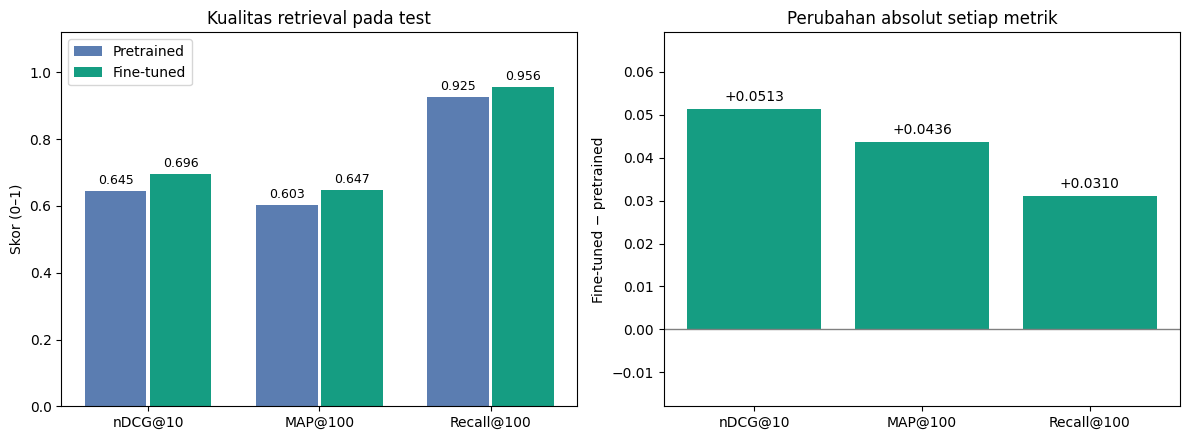

nDCG@10: 0.6451 → 0.6964; meningkat (+0.0513).
MAP@100: 0.6031 → 0.6466; meningkat (+0.0436).
Recall@100: 0.9250 → 0.9560; meningkat (+0.0310).


In [16]:
import matplotlib.pyplot as plt
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

if "ROOT" not in globals():
    ROOT = (Path.cwd() / "outputs" / "scifact_laptop").resolve()
ROOT = Path(ROOT)

# Gunakan hasil runtime; bila tidak ada, muat artefak tanpa menjalankan training.
for variable, filename in {
    "baseline_run": "run_pretrained_top100.json",
    "final_run": "run_finetuned_top100.json",
}.items():
    if variable not in globals():
        artifact = ROOT / filename
        if not artifact.exists():
            raise FileNotFoundError(f"{artifact} belum tersedia. Jalankan evaluasi cell 12–15 atau unggah artefaknya.")
        globals()[variable] = json.loads(artifact.read_text(encoding="utf-8"))

for variable, filename in {
    "baseline_per_query": "per_query_pretrained.csv",
    "final_per_query": "per_query_finetuned.csv",
}.items():
    if variable not in globals():
        globals()[variable] = pd.read_csv(ROOT / filename, dtype={"query_id": str})

if "corpus" not in globals():
    documents = json.loads((ROOT / "documents.json").read_text(encoding="utf-8"))
    corpus = {str(doc["_id"]): doc for doc in documents}

# Qrels test, query, dan teks tidak bisa disimpulkan dari ranking saja.
if "qrels_test" not in globals() or "queries" not in globals():
    context_path = ROOT / "analysis_context.json"
    if not context_path.exists():
        raise FileNotFoundError("Qrels test/queries tidak ada. Jalankan cell 03–04 atau unggah analysis_context.json dari run sebelumnya.")
    restored_context = json.loads(context_path.read_text(encoding="utf-8"))
    qrels_test, queries = restored_context["qrels_test"], restored_context["queries"]

ANALYSIS_DIR = ROOT / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / "analysis_context.json").write_text(
    json.dumps({"qrels_test": qrels_test, "queries": {q: queries[q] for q in qrels_test}},
               ensure_ascii=False, indent=2), encoding="utf-8")

METRICS = ["nDCG@10", "MAP@100", "Recall@100"]
COLORS = {"Pretrained": "#5B7DB1", "Fine-tuned": "#159D82"}
metric_table = pd.DataFrame({
    "Pretrained": baseline_per_query[METRICS].mean(),
    "Fine-tuned": final_per_query[METRICS].mean(),
})
metric_table["Delta absolut"] = metric_table["Fine-tuned"] - metric_table["Pretrained"]
metric_table["Delta poin persentase"] = metric_table["Delta absolut"] * 100
metric_table.to_csv(ANALYSIS_DIR / "metric_comparison.csv", index_label="metric")
display(metric_table.round(4))

def save_analysis_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(ANALYSIS_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(METRICS))
for offset, model_name in [(-0.19, "Pretrained"), (0.19, "Fine-tuned")]:
    bars = axes[0].bar(x + offset, metric_table[model_name], width=0.36,
                       label=model_name, color=COLORS[model_name])
    axes[0].bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
axes[0].set(xticks=x, xticklabels=METRICS, ylim=(0, 1.12),
            ylabel="Skor (0–1)", title="Kualitas retrieval pada test")
axes[0].legend(loc="upper left")
delta = metric_table["Delta absolut"].to_numpy()
bars = axes[1].bar(METRICS, delta, color=["#159D82" if v >= 0 else "#CF6057" for v in delta])
axes[1].bar_label(bars, labels=[f"{v:+.4f}" for v in delta], padding=4)
axes[1].axhline(0, color="gray", linewidth=1)
margin = max(float(np.max(np.abs(delta))) * 0.35, 0.01)
axes[1].set(ylim=(min(0, float(delta.min())) - margin, max(0, float(delta.max())) + margin),
            ylabel="Fine-tuned − pretrained", title="Perubahan absolut setiap metrik")
save_analysis_figure(fig, "01_metric_comparison.png")
for metric, row in metric_table.iterrows():
    direction = "meningkat" if row["Delta absolut"] > 1e-10 else "menurun" if row["Delta absolut"] < -1e-10 else "tetap"
    print(f'{metric}: {row["Pretrained"]:.4f} → {row["Fine-tuned"]:.4f}; {direction} ({row["Delta absolut"]:+.4f}).')


## 15B · Perubahan performa setiap query

Titik di atas diagonal menunjukkan nDCG@10 fine-tuned lebih tinggi. Titik di bawahnya menunjukkan penurunan.
Titik dapat saling bertumpuk. Grafik kedua menghitung query membaik/tetap/menurun untuk masing-masing metrik
dengan toleransi numerik `1e-10`. Rata-rata meningkat tidak berarti semua query membaik.


,Membaik,Tetap,Menurun
metric,,,
nDCG@10,63,208,29
MAP@100,84,183,33
Recall@100,10,289,1


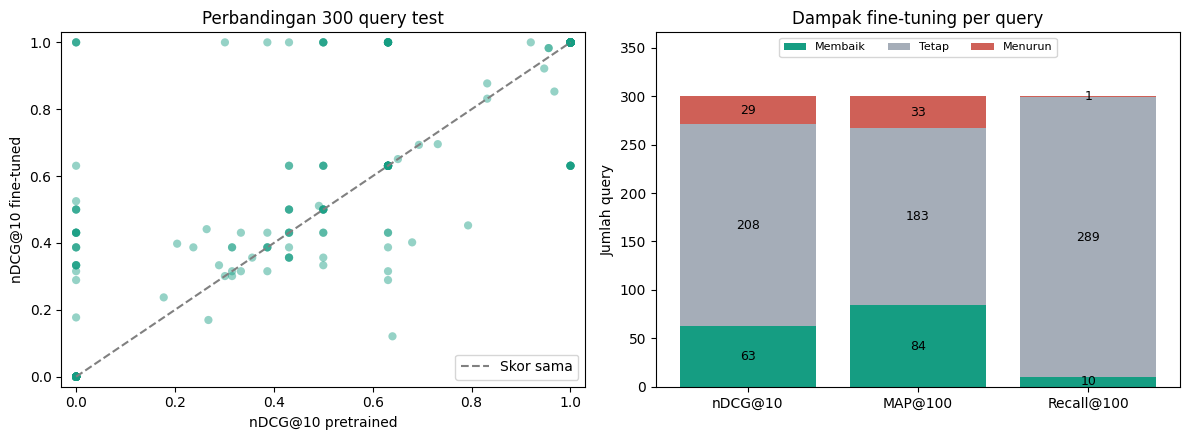

In [17]:
before = baseline_per_query.copy()
after = final_per_query.copy()
before["query_id"] = before["query_id"].astype(str)
after["query_id"] = after["query_id"].astype(str)
assert set(before["query_id"]) == set(after["query_id"]) == set(qrels_test)
paired = before.merge(after, on="query_id", suffixes=("_before", "_after"), validate="one_to_one")
changes = []
for metric in METRICS:
    diff = paired[f"{metric}_after"] - paired[f"{metric}_before"]
    paired[f"delta_{metric}"] = diff
    changes.append({"metric": metric, "Membaik": int((diff > 1e-10).sum()),
                    "Tetap": int((diff.abs() <= 1e-10).sum()), "Menurun": int((diff < -1e-10).sum())})
change_table = pd.DataFrame(changes).set_index("metric")
paired.to_csv(ANALYSIS_DIR / "paired_query_metrics.csv", index=False)
change_table.to_csv(ANALYSIS_DIR / "query_change_counts.csv")
display(change_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(paired["nDCG@10_before"], paired["nDCG@10_after"], alpha=0.45,
                s=35, color=COLORS["Fine-tuned"], edgecolors="none")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Skor sama")
axes[0].set(xlim=(-0.03, 1.03), ylim=(-0.03, 1.03), xlabel="nDCG@10 pretrained",
            ylabel="nDCG@10 fine-tuned", title=f"Perbandingan {len(paired)} query test")
axes[0].legend()
bottom = np.zeros(len(METRICS))
for label, color in [("Membaik", "#159D82"), ("Tetap", "#A5ADB8"), ("Menurun", "#CF6057")]:
    values = change_table.loc[METRICS, label].to_numpy()
    bars = axes[1].bar(METRICS, values, bottom=bottom, label=label, color=color)
    axes[1].bar_label(bars, labels=[str(v) if v else "" for v in values], label_type="center", fontsize=9)
    bottom += values
axes[1].set(ylabel="Jumlah query", title="Dampak fine-tuning per query", ylim=(0, len(paired) * 1.22))
axes[1].legend(loc="upper center", ncol=3, fontsize=8)
save_analysis_figure(fig, "02_query_changes.png")


## 15C · Recall@K dan matriks transisi Hit@10

Recall@K adalah proporsi seluruh dokumen relevan yang ditemukan pada K hasil. Hit@K adalah proporsi query
yang memperoleh **minimal satu** dokumen relevan pada K hasil. Keduanya berbeda bila satu query memiliki beberapa positive.

Matriks 2×2 membandingkan **keberhasilan query sebelum dan sesudah fine-tuning**, bukan confusion matrix klasifikasi:
baris = pretrained, kolom = fine-tuned. `Gagal → Berhasil` berarti query baru memperoleh minimal satu positive
di top-10; `Berhasil → Gagal` menunjukkan regresi. Matriks ini tidak memberi label SUPPORT/REFUTE.
Dokumen tanpa judgment tidak dihitung sebagai positive; karena anotasi dapat tidak lengkap, istilah “gagal” di sini
hanya berarti tidak menemukan dokumen relevan **menurut qrels** dalam top-10.


,K,Recall@K,Hit@K,model
0,1,0.482333,0.503333,Pretrained
1,3,0.660333,0.683333,Pretrained
2,5,0.737944,0.753333,Pretrained
3,10,0.783333,0.793333,Pretrained
4,20,0.837333,0.846667,Pretrained
5,50,0.892000,0.900000,Pretrained
6,100,0.925000,0.926667,Pretrained
7,1,0.530556,0.546667,Fine-tuned
8,3,0.682056,0.706667,Fine-tuned
9,5,0.774278,0.793333,Fine-tuned


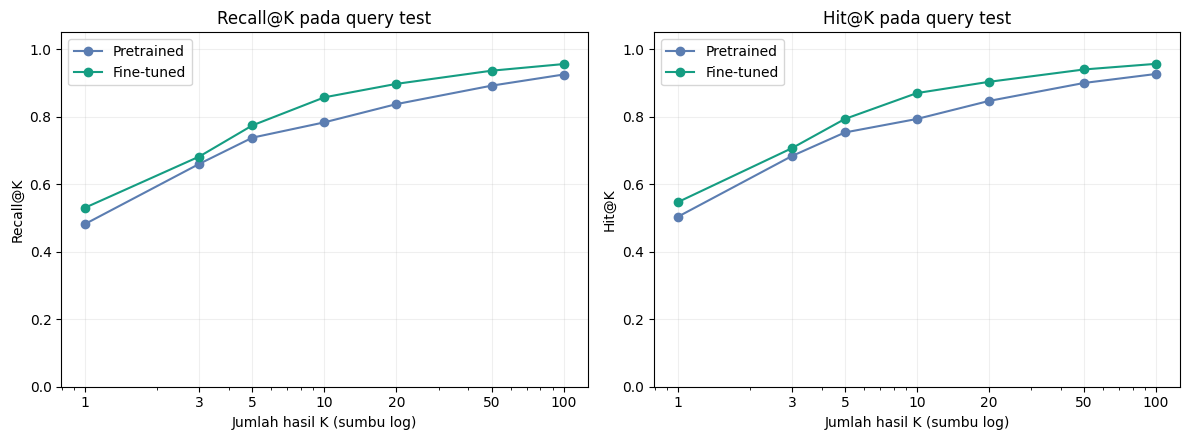

,Fine-tuned gagal,Fine-tuned berhasil
Pretrained gagal,39,23
Pretrained berhasil,0,238


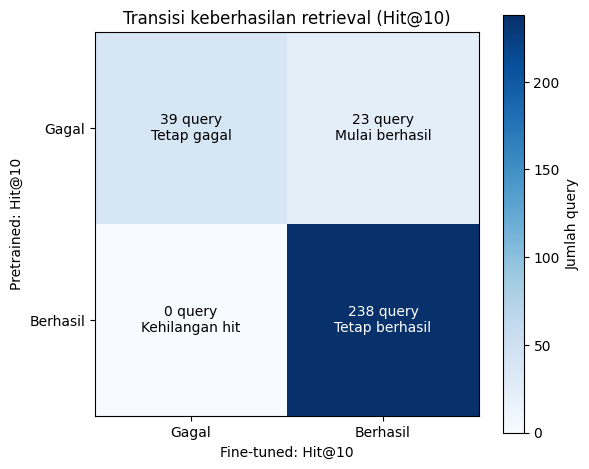

Mulai berhasil: 23 query; kehilangan hit: 0 query.


In [18]:
def retrieval_curve(run, judgments, cutoffs):
    assert set(run) == set(judgments)
    rows = []
    for k in cutoffs:
        recalls, hits = [], []
        for qid, judged in judgments.items():
            relevant = {str(d) for d, rel in judged.items() if rel > 0}
            assert relevant
            ranked = [str(did) for did, score in run[qid]]
            assert len(ranked) >= k, f"Ranking {qid} kurang dari {k} dokumen."
            assert len(set(ranked)) == len(ranked)
            found = len(set(ranked[:k]) & relevant)
            recalls.append(found / len(relevant))
            hits.append(float(found > 0))
        rows.append({"K": k, "Recall@K": float(np.mean(recalls)), "Hit@K": float(np.mean(hits))})
    return pd.DataFrame(rows)

cutoffs = [1, 3, 5, 10, 20, 50, 100]
curves = pd.concat([
    retrieval_curve(baseline_run, qrels_test, cutoffs).assign(model="Pretrained"),
    retrieval_curve(final_run, qrels_test, cutoffs).assign(model="Fine-tuned"),
], ignore_index=True)
curves.to_csv(ANALYSIS_DIR / "recall_hit_at_k.csv", index=False)
display(curves)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for model_name in COLORS:
    subset = curves[curves["model"] == model_name]
    for ax, metric in zip(axes, ["Recall@K", "Hit@K"]):
        ax.plot(subset["K"], subset[metric], marker="o", label=model_name, color=COLORS[model_name])
        ax.set(xscale="log", xticks=cutoffs, xticklabels=cutoffs, ylim=(0, 1.05),
               xlabel="Jumlah hasil K (sumbu log)", ylabel=metric, title=f"{metric} pada query test")
        ax.grid(alpha=0.2)
        ax.legend()
save_analysis_figure(fig, "03_recall_hit_curves.png")

def hit_transition(before_run, after_run, judgments, k=10):
    assert set(before_run) == set(after_run) == set(judgments)
    matrix = np.zeros((2, 2), dtype=int)
    details = []
    for qid, judged in judgments.items():
        relevant = {str(d) for d, rel in judged.items() if rel > 0}
        assert len(before_run[qid]) >= k and len(after_run[qid]) >= k
        old_hit = int(bool({str(d) for d, _ in before_run[qid][:k]} & relevant))
        new_hit = int(bool({str(d) for d, _ in after_run[qid][:k]} & relevant))
        matrix[old_hit, new_hit] += 1
        details.append({"query_id": qid, "pretrained_hit": old_hit, "finetuned_hit": new_hit})
    return matrix, pd.DataFrame(details)

transition, hit_details = hit_transition(baseline_run, final_run, qrels_test, k=10)
transition_table = pd.DataFrame(transition, index=["Pretrained gagal", "Pretrained berhasil"],
                                columns=["Fine-tuned gagal", "Fine-tuned berhasil"])
transition_table.to_csv(ANALYSIS_DIR / "hit10_transition.csv")
hit_details.to_csv(ANALYSIS_DIR / "hit10_per_query.csv", index=False)
display(transition_table)
fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(transition, cmap="Blues", vmin=0, vmax=max(1, int(transition.max())))
labels = [["Tetap gagal", "Mulai berhasil"], ["Kehilangan hit", "Tetap berhasil"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{transition[i, j]} query\n{labels[i][j]}", ha="center", va="center",
                color="white" if transition[i, j] > transition.max() / 2 else "black")
ax.set(xticks=[0, 1], xticklabels=["Gagal", "Berhasil"], yticks=[0, 1], yticklabels=["Gagal", "Berhasil"],
       xlabel="Fine-tuned: Hit@10", ylabel="Pretrained: Hit@10", title="Transisi keberhasilan retrieval (Hit@10)")
fig.colorbar(heatmap, ax=ax, label="Jumlah query")
save_analysis_figure(fig, "04_hit10_transition.png")
print(f"Mulai berhasil: {transition[0, 1]} query; kehilangan hit: {transition[1, 0]} query.")


## 15D · Contoh ranking dan bahan pembahasan

Pilih masing-masing satu query dengan delta nDCG@10 positif terbesar, negatif terbesar, dan satu query yang tetap,
jika kelompok tersebut tersedia. Pemilihan ekstrem membantu diagnosis, tetapi bukan sampel representatif seluruh test.

Tabel pertama membandingkan top-5 kedua model pada posisi yang sama. Tabel kedua melacak posisi **semua positive qrels**;
`>100 / tidak ada di run` bukan berarti dokumen tidak ada di corpus. Judul dan abstrak diambil dari sumber asli.
Skor cosine ditampilkan sebagai konteks dalam masing-masing model; perubahan skor antar-encoder bukan bukti relevansi.
Jangan memakai analisis test ini untuk memilih ulang hyperparameter pada test yang sama.


In [19]:
selected = []
for label, mask, ascending in [
    ("Peningkatan terbesar", paired["delta_nDCG@10"] > 1e-10, False),
    ("Penurunan terbesar", paired["delta_nDCG@10"] < -1e-10, True),
    ("Skor tetap", paired["delta_nDCG@10"].abs() <= 1e-10, True),
]:
    candidates = paired.loc[mask].sort_values(["delta_nDCG@10", "query_id"], ascending=[ascending, True])
    if candidates.empty:
        print(f"Tidak ada query untuk kategori: {label}.")
    else:
        selected.append((label, candidates.iloc[0]["query_id"]))

def compare_query_rankings(qid, top_k=5):
    relevant = {str(d) for d, rel in qrels_test[qid].items() if rel > 0}
    rows = []
    for position in range(top_k):
        row = {"rank": position + 1}
        for label, run in [("pretrained", baseline_run), ("finetuned", final_run)]:
            if position >= len(run[qid]):
                continue
            did, score = run[qid][position]
            did = str(did)
            row.update({f"{label}_id": did, f"{label}_title": corpus[did]["title"],
                        f"{label}_cosine": float(score),
                        f"{label}_qrels": "Relevan" if did in relevant else "Tidak berlabel relevan"})
        rows.append(row)
    positions = []
    for did in sorted(relevant):
        record = {"document_id": did, "title": corpus[did]["title"], "abstract": corpus[did]["text"]}
        for label, run in [("pretrained", baseline_run), ("finetuned", final_run)]:
            rank = next((i for i, (d, _) in enumerate(run[qid], 1) if str(d) == did), None)
            record[f"rank_{label}"] = rank if rank is not None else f">{len(run[qid])} / tidak ada di run"
        positions.append(record)
    return pd.DataFrame(rows), pd.DataFrame(positions)

case_summaries = []
for label, qid in selected:
    record = paired.set_index("query_id").loc[qid]
    print(f"\n{label} | query {qid}")
    print(queries[qid]["text"])
    print(f'nDCG@10: {record["nDCG@10_before"]:.4f} → {record["nDCG@10_after"]:.4f}')
    ranking_table, positive_positions = compare_query_rankings(qid)
    display(ranking_table)
    print("Posisi dokumen relevan berdasarkan qrels:")
    display(positive_positions)
    ranking_table.to_csv(ANALYSIS_DIR / f"example_{qid}_top5.csv", index=False)
    positive_positions.to_csv(ANALYSIS_DIR / f"example_{qid}_positive_positions.csv", index=False)
    case_summaries.append({"category": label, "query_id": qid, "query": queries[qid]["text"],
        "nDCG_before": float(record["nDCG@10_before"]), "nDCG_after": float(record["nDCG@10_after"]),
        "delta_nDCG": float(record["delta_nDCG@10"])})
pd.DataFrame(case_summaries).to_csv(ANALYSIS_DIR / "example_summary.csv", index=False)
print("\nBahan pembahasan: dokumen relevan mana yang naik/turun, apa isi bukti dalam abstraknya,")
print("dan apakah ada kandidat mirip topik tetapi tidak berlabel relevan? Jangan simpulkan penyebab dari skor saja.")
print("Grafik dan tabel tersimpan di:", ANALYSIS_DIR)
print("Jalankan ulang cell 18 ekspor setelah analisis agar ZIP dan checksum mencakup file baru.")



Peningkatan terbesar | query 1175
The PPR MDA5 has two N-terminal CARD domains.
nDCG@10: 0.0000 → 1.0000


,rank,pretrained_id,pretrained_title,pretrained_cosine,pretrained_qrels,finetuned_id,finetuned_title,finetuned_cosine,finetuned_qrels
0,1,20725212,Chaperoning 5S RNA assembly.,0.341310,Tidak berlabel relevan,31272411,Immune signaling by RIG-I-like receptors.,0.472588,Relevan
1,2,18467982,A cluster of ribosome synthesis factors regula...,0.300390,Tidak berlabel relevan,20725212,Chaperoning 5S RNA assembly.,0.462920,Tidak berlabel relevan
2,3,31107919,Differential Requirement of the Extracellular ...,0.288876,Tidak berlabel relevan,16058322,"MDA5 and PTPN2, two candidate genes for type 1...",0.399755,Tidak berlabel relevan
3,4,3610282,Phase-plate cryo-EM structure of a biased agon...,0.284537,Tidak berlabel relevan,3610282,Phase-plate cryo-EM structure of a biased agon...,0.352130,Tidak berlabel relevan
4,5,3127341,Polymorphism and ligand dependent changes in h...,0.274490,Tidak berlabel relevan,18467982,A cluster of ribosome synthesis factors regula...,0.341404,Tidak berlabel relevan


Posisi dokumen relevan berdasarkan qrels:


,document_id,title,abstract,rank_pretrained,rank_finetuned
0,31272411,Immune signaling by RIG-I-like receptors.,"The RIG-I-like receptors (RLRs) RIG-I, MDA5, a...",>100 / tidak ada di run,1



Penurunan terbesar | query 133
Assembly of invadopodia is triggered by focal generation of phosphatidylinositol-3,4-biphosphate and the activation of the nonreceptor tyrosine kinase Src.
nDCG@10: 0.6399 → 0.1208


,rank,pretrained_id,pretrained_title,pretrained_cosine,pretrained_qrels,finetuned_id,finetuned_title,finetuned_cosine,finetuned_qrels
0,1,12640810,Cortactin regulates cofilin and N-WASp activit...,0.565517,Relevan,6492658,A Null Mutation in Inositol Polyphosphate 4-Ph...,0.478469,Tidak berlabel relevan
1,2,86694016,Molecular mechanisms of invadopodium formation...,0.537503,Tidak berlabel relevan,25515662,In vitro substrate specificity of protein tyro...,0.477181,Tidak berlabel relevan
2,3,17934082,Membrane lipids in invadopodia and podosomes: ...,0.506442,Relevan,22025252,Changes in the levels of inositol phosphates a...,0.451458,Tidak berlabel relevan
3,4,6492658,A Null Mutation in Inositol Polyphosphate 4-Ph...,0.504186,Tidak berlabel relevan,3155374,"Phosphatidylinositol 4,5-Bisphosphate Function...",0.443761,Tidak berlabel relevan
4,5,16280642,Sequential signals toward podosome formation i...,0.479131,Relevan,14328288,A family of phosphoinositide 3-kinases in Dros...,0.441199,Tidak berlabel relevan


... (3 outputs left out)

,rank,pretrained_id,pretrained_title,pretrained_cosine,pretrained_qrels,finetuned_id,finetuned_title,finetuned_cosine,finetuned_qrels
0,1,9745001,Radioiodine treatment of multinodular non-toxi...,0.850270,Relevan,9745001,Radioiodine treatment of multinodular non-toxi...,0.866819,Relevan
1,2,43122426,131-I radioiodine therapy for hyperthyroidism ...,0.708764,Tidak berlabel relevan,6751418,Dosimetry and risk estimates of radioiodine th...,0.724864,Tidak berlabel relevan
2,3,6751418,Dosimetry and risk estimates of radioiodine th...,0.685716,Tidak berlabel relevan,43122426,131-I radioiodine therapy for hyperthyroidism ...,0.723979,Tidak berlabel relevan
3,4,37912677,Dose-response study on thyrotoxic patients und...,0.609646,Tidak berlabel relevan,37912677,Dose-response study on thyrotoxic patients und...,0.616139,Tidak berlabel relevan
4,5,26026009,Magnetic resonance imaging for volume estimati...,0.412116,Tidak berlabel relevan,26026009,Magnetic resonance imaging for volume estimati...,0.412044,Tidak berlabel relevan


Posisi dokumen relevan berdasarkan qrels:


,document_id,title,abstract,rank_pretrained,rank_finetuned
0,9745001,Radioiodine treatment of multinodular non-toxi...,OBJECTIVE To investigate the long term effect ...,1,1



Bahan pembahasan: dokumen relevan mana yang naik/turun, apa isi bukti dalam abstraknya,
dan apakah ada kandidat mirip topik tetapi tidak berlabel relevan? Jangan simpulkan penyebab dari skor saja.
Grafik dan tabel tersimpan di: C:\Users\amrin\OneDrive\Desktop\kuli\TKI\outputs\scifact_laptop\analysis
Jalankan ulang cell 18 ekspor setelah analisis agar ZIP dan checksum mencakup file baru.


## 16 · Fungsi semantic search

Query kosong ditolak. Query terlalu panjang dipotong oleh tokenizer dengan pemberitahuan. Hasil mengambil judul dan abstrak asli, tanpa membuat judul atau abstrak baru. Cosine similarity bukan probabilitas relevansi.


In [20]:
def search(query, top_k=5):
    query = clean_text(query)
    if not query:
        raise ValueError("Query tidak boleh kosong.")
    if not isinstance(top_k, int) or not 1 <= top_k <= len(doc_ids):
        raise ValueError(f"top_k harus integer antara 1 dan {len(doc_ids)}.")
    length = len(final_encoder.tokenizer(query, truncation=False, verbose=False)["input_ids"])
    if length > final_encoder.max_seq_length:
        print(f"Query {length} token; input model dipotong sampai {final_encoder.max_seq_length} token.")
    vector = encode_texts(final_encoder, [query])
    ranked = rank_queries(vector, document_vectors, doc_ids, top_k)[0]
    return [{"rank": i, "document_id": did, "similarity": score,
             "title": corpus[did]["title"], "abstract": corpus[did]["text"]}
            for i, (did, score) in enumerate(ranked, 1)]

def print_results(query, results, preview_chars=500):
    print(f'Search results for: "{query}"\n')
    for row in results:
        abstract = row["abstract"]
        preview = abstract[:preview_chars] + ("..." if len(abstract) > preview_chars else "")
        print(f'{row["rank"]}. {row["title"]}')
        print(f'   Similarity: {row["similarity"]:.4f}')
        print(f'   Document ID: {row["document_id"]}')
        print(f'   {preview}\n')


## 17 · Demo input pengguna

Pertanyaan vitamin D adalah demo pencarian berbahasa Inggris. Judul dan skor aktual mengikuti isi SciFact; contoh skor 0.89 pengguna bukan target training. Query demo tidak memiliki qrels sehingga tidak diberi nilai nDCG/MAP/Recall.


In [21]:
USER_QUERY = "Does vitamin D improve bone density?"
demo_results = search(USER_QUERY, top_k=CFG["display_top_k"])
print_results(USER_QUERY, demo_results)
save_json({"query": USER_QUERY, "results": demo_results}, ROOT / "demo_search.json")


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Search results for: "Does vitamin D improve bone density?"

1. Vitamin D and obesity: current perspectives and future directions.
   Similarity: 0.6913
   Document ID: 21553394
   In recent years, new functional roles of vitamin D beyond its traditional role in calcium homoeostasis and bone metabolism have emerged linking the fat-soluble vitamin to various non-communicable diseases. Vitamin D deficiency (25-hydroxyvitamin D (25(OH)D) < 25-30 nmol/l) and sub-optimal status (25(OH)D < 50-100 nmol/l) are increasingly associated with unfavourable metabolic phenotypes, including insulin resistance, type 2 diabetes and CVD; conditions also commonly linked with overweight and ob...

2. Estimation of optimal serum concentrations of 25-hydroxyvitamin D for multiple health outcomes.
   Similarity: 0.6468
   Document ID: 4462079
   Recent evidence suggests that vitamin D intakes above current recommendations may be associated with better health outcomes. However, optimal serum concentrations of 2

## 18 · Simpan artefak dan ZIP di laptop

Seluruh hasil tetap tersedia di folder lokal setelah Jupyter ditutup. ZIP berisi model, embedding, metadata, grafik dan tabel analisis, serta konfigurasi dan versi paket. Notebook sumber tidak termasuk ZIP; simpan file `.ipynb` beserta outputnya melalui menu Save.


In [22]:
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], check=True, capture_output=True, text=True)
(ROOT / "requirements_frozen.txt").write_text(freeze.stdout, encoding="utf-8")
artifact_files = sorted(p for p in ROOT.rglob("*") if p.is_file() and "checkpoints" not in p.relative_to(ROOT).parts)
checksums = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
             for p in artifact_files if p.name != "checksums.json"}
save_json(checksums, ROOT / "checksums.json")
import zipfile
archive = ROOT.parent / "scifact_laptop_artifacts.zip"
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(ROOT.rglob("*")):
        if path.is_file() and "checkpoints" not in path.relative_to(ROOT).parts:
            zf.write(path, arcname=str(path.relative_to(ROOT)))
print("Folder output:", ROOT)
print("ZIP lokal:", archive)
print("Untuk inference sesi berikutnya: muat model_final, document_embeddings.npy, doc_ids.json, documents.json; tidak perlu training ulang.")


Folder output: C:\Users\amrin\OneDrive\Desktop\kuli\TKI\outputs\scifact_laptop
ZIP lokal: C:\Users\amrin\OneDrive\Desktop\kuli\TKI\outputs\scifact_laptop_artifacts.zip
Untuk inference sesi berikutnya: muat model_final, document_embeddings.npy, doc_ids.json, documents.json; tidak perlu training ulang.


## Sumber dan batas interpretasi

- [Model card MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)
- [Corpus dan queries SciFact](https://huggingface.co/datasets/BeIR/scifact)
- [Qrels train/test](https://huggingface.co/datasets/BeIR/scifact-qrels)
- [Training Sentence Transformers](https://sbert.net/docs/sentence_transformer/training_overview.html)
- [MNRL](https://sbert.net/docs/package_reference/sentence_transformer/losses.html#sentence_transformers.losses.MultipleNegativesRankingLoss)
- [No-duplicates sampler](https://sbert.net/docs/package_reference/sentence_transformer/sampler.html)